In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [3]:
df = pd.read_csv("housing_regression.csv")

In [4]:
df.head()

,Area_sqft,Bedrooms,Bathrooms,Property_Age_years,Distance_to_City_Center_km,Parking_Spaces,Neighborhood_Score_1_to_10,Price_INR
0,857,1,1,12,6.0,0,3.0,17172515
1,3596,7,6,8,15.4,2,4.1,74140796
2,3118,5,4,31,9.0,1,3.6,62282514
3,2255,3,3,9,29.7,0,9.0,45275859
4,2232,4,4,7,26.6,2,7.9,46323817


In [5]:
X = df[['Area_sqft','Bedrooms','Bathrooms','Property_Age_years','Distance_to_City_Center_km','Parking_Spaces','Neighborhood_Score_1_to_10']]
y = df[['Price_INR']]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
model = LinearRegression()

In [8]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 7)","[[ 18003.28,552801.84,699706.46,...,-89121.87,249277.29,299686.48]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Area_sqft','Bedrooms','Bathrooms',...,'Distance_to_City_Center_km', 'Parking_Spaces','Neighborhood_Score_1_to_10']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1146583.16]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7


In [9]:
y_pred = model.predict(X_test)
y_pred

array([[19850495.68843427],
       [74248707.31141287],
       [18419861.96474101],
       ...,
       [75842563.57638946],
       [71723822.35240453],
       [69331521.9356542 ]])

In [10]:
r2 = model.score(X_test, y_test)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("R2 Score:", r2)
print("MSE:", mse)
print("RMSE:", rmse)

R2 Score: 0.999641048579816
MSE: 189027085728.57333
RMSE: 434772.4528170723


In [11]:
print("Coefficients:", model.coef_)

print("Intercept:", model.intercept_)

Coefficients: [[ 18003.28135323 552801.83960817 699706.45922324 -44449.57794328
  -89121.8692173  249277.28676163 299686.48150452]]
Intercept: [1146583.15833715]


In [12]:
comparison = pd.DataFrame({
    'Actual Price': y_test['Price_INR'].values,
    'Predicted Price': y_pred.flatten()
})

comparison.head(10)

,Actual Price,Predicted Price
0,19791997,1.985050e+07
1,74414322,7.424871e+07
2,18750957,1.841986e+07
3,83282135,8.318908e+07
4,59397255,5.899822e+07
5,62202937,6.174897e+07
6,38925218,3.860303e+07
7,61145409,6.099585e+07
8,70572544,7.028704e+07
9,77968291,7.740149e+07


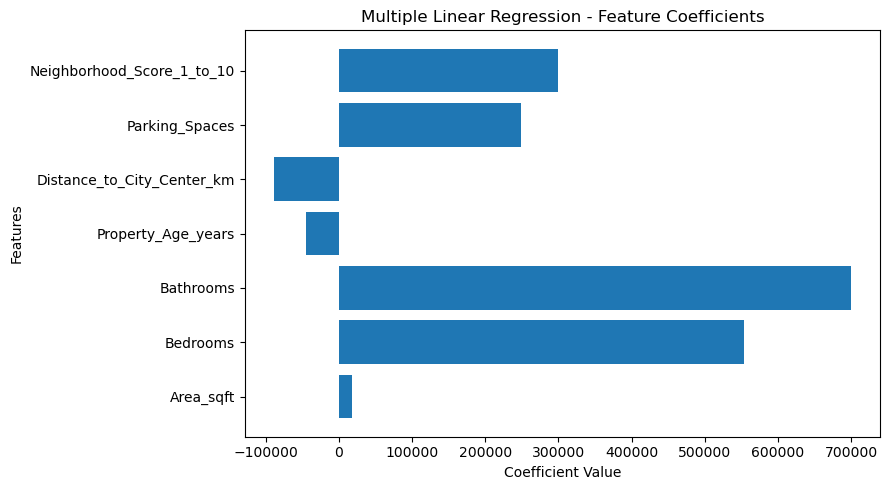

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_.ravel()
})

plt.figure(figsize=(9, 5))

plt.barh(
    coefficients['Feature'],
    coefficients['Coefficient']
)

plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("Multiple Linear Regression - Feature Coefficients")

plt.tight_layout()
plt.show()